# Simple Battery Degradation PINN

**Goal:** Fit lithium-ion *calendar ageing* (loss of capacity during storage) at **25 °C** .

**What we will build:** 1 input (storage time) → 2 hidden layers (32 neurons each) → 1 output (state of health, SOH). We will train against only **11 data points**, while enforcing a differential equation at 30 additional time points (collocation points).

**Important scope:** This is a simple example. The physics is an *empirical calendar-ageing equation* embedded in loss function.

**What we will predict:** Given the number of days a battery has been stored at 25°C, predict its remaining capacity. (Normalized remaining capacity Q, is equivalent to SOH.)

**Source Of Data**

The experimental data was extracted from:

Naumann, M. et al., Analysis and Modeling of Calendar Aging of a Commercial LiFePO₄/Graphite Cell, Journal of The Electrochemical Society.

📄 Paper:
https://iopscience.iop.org/article/10.1149/2.1181714jes

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

# Random seed so results are reproducible.
torch.manual_seed(7)


## Step 1 — Inspect and Normalize the capacity-fade data

The data contain storage duration (in days) and fractional capacity loss at 25 °C. We convert capacity loss to remaining-capacity SOH by `SOH = 1 - loss`.



Input shape: (11, 1) (11 rows x 1 input)
Output shape: (11, 1) (11 rows x 1 output)


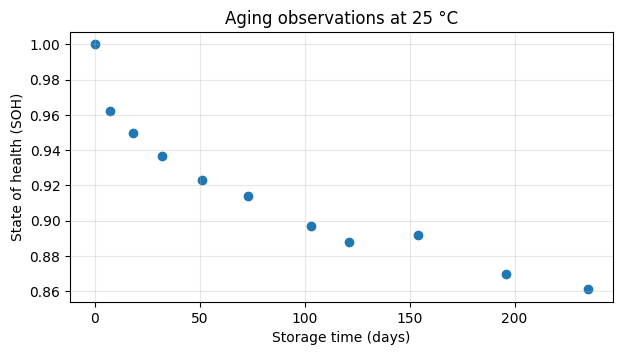

In [ ]:
DAYS = [0, 7, 18, 32, 51, 73, 103, 121, 154, 196, 235]
CAPACITY_LOSS = [0.000, 0.038, 0.050, 0.063, 0.077, 0.086, 0.103, 0.112, 0.108, 0.130, 0.139]
MAX_DAYS = 235.0

# Normalize input time: s = t/235, so s is between 0 and 1.
s_data = torch.tensor(DAYS, dtype=torch.float32).reshape(-1, 1) / MAX_DAYS
soh_data = 1.0 - torch.tensor(CAPACITY_LOSS, dtype=torch.float32).reshape(-1, 1)
print('Input shape:', tuple(s_data.shape), '(11 rows x 1 input)')
print('Output shape:', tuple(soh_data.shape), '(11 rows x 1 output)')

plt.figure(figsize=(7, 3.5))
plt.scatter(DAYS, soh_data[:, 0].numpy())
plt.xlabel('Storage time (days)')
plt.ylabel('State of health (SOH)')
plt.title('Aging observations at 25 °C')
plt.grid(alpha=0.3)
plt.show()

## Step 2 — Define the neural network

It maps $s$ (normalized time) to $Q(s)$ (predicted SOH).

It also contains two learnable, nonnegative scalar coefficients, $A$ and $B$, that describe a simple ageing curve:

$$Q(s)=1-A\sqrt{s}-Bs$$

We use `softplus` to keep them nonnegative. They are **empirical coefficients**.

In [ ]:
class BatteryPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 1),
        )
        self.raw_A = nn.Parameter(torch.tensor(-2.5))
        self.raw_B = nn.Parameter(torch.tensor(-3.5))

    @property
    def A(self):
        return F.softplus(self.raw_A)

    @property
    def B(self):
        return F.softplus(self.raw_B)

    def forward(self, s):
        return self.net(s)

model = BatteryPINN()
print(model)
print('Initial A:', round(model.A.item(), 4), '| initial B:', round(model.B.item(), 4))

BatteryPINN(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Initial A: 0.0789 | initial B: 0.0298


## Step 3 — Understand the *physics loss*

The crucial PINN idea is to make the neural network approximately follow a differential equation. Differentiate the empirical law

$$Q(s)=1-A\sqrt{s}-Bs$$

with respect to $s$:

$$\frac{dQ}{ds}=-\frac{A}{2\sqrt{s}}-B.$$

Rearrange it into the **residual equation** (zero for a perfect solution):

$$\boxed{R(s)=\sqrt{s}\frac{dQ_\theta}{ds}+\frac{A}{2}+B\sqrt{s}=0}$$

`torch.autograd.grad` calculates the derivative of the neural network **with respect to its input time**. We then penalize `mean(residual**2)`.

The domain starts at **s = 0.02**, not zero, because the original square-root derivative is singular at $s=0$. We handle $Q(0)=1$ through a separate initial-condition loss.

**Why did we differentiate the equation?**
The NN might memorize the formula and just fit the curve. We will loose out purpose of finding a good generalizable model. By using the derivative, we are enforcing the underlying dynamics rather than enforcing exact curve shape.


So our three objectives are:

- **Data loss**: match observed SOH at 11 measurement times.
- **Physics loss**: obey the ageing ODE at 30 *collocation points*.
- **Initial-condition loss**: start at SOH = 1.

$$ \large L=L_{data}+\lambda_{phys}L_{physics}+\lambda_{initial}L_{initial}$$

In [ ]:
def compute_losses(model, physics_weight=0.1, initial_weight=1.0):
    # 1. Data loss: does the network fit the observed SOH?
    predicted = model(s_data)
    data_loss = ((predicted - soh_data) ** 2).mean()

    # 2. Physics loss: does the curve follow the ODE at extra time points?
    s_physics = torch.linspace(0.02, 1.0, 30).reshape(-1, 1)
    s_physics.requires_grad_(True)
    q_physics = model(s_physics)
    dq_ds = torch.autograd.grad(
        outputs=q_physics,
        inputs=s_physics,
        grad_outputs=torch.ones_like(q_physics),
        create_graph=True  # essential so backprop can learn from the derivative
    )[0]
    residual = (s_physics.sqrt() * dq_ds
                + model.A / 2.0
                + model.B * s_physics.sqrt())
    physics_loss = (residual ** 2).mean()

    # 3. Initial condition: Q(0) must be close to 1.
    initial_loss = (model(torch.zeros(1, 1)) - 1.0).square().mean()

    total = data_loss + physics_weight * physics_loss + initial_weight * initial_loss
    return total, data_loss, physics_loss, initial_loss

## Step 4 — Train the PINN

Start with `EPOCHS = 2000`.

The `PHYSICS_WEIGHT` variable
- `0.1`: physics-informed model (our default).
- `0.0`: same neural network **without** the physics loss.

**Note:** Learnable physics coefficients are used only in the physics loss.

In [ ]:
EPOCHS = 2000
PHYSICS_WEIGHT = 0.1
INITIAL_WEIGHT = 1.0

# Reset weights each time this cell runs so comparisons are fair.
torch.manual_seed(7)
model = BatteryPINN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
history = []

for epoch in range(EPOCHS):
    optimizer.zero_grad()
    total, data_loss, physics_loss, initial_loss = compute_losses(
        model, PHYSICS_WEIGHT, INITIAL_WEIGHT
    )
    total.backward()   # gradients of the total loss w.r.t. parameters
    optimizer.step()   # updates network weights and ageing coefficients
    history.append([total.item(), data_loss.item(),
                    physics_loss.item(), initial_loss.item()])
    if epoch % 400 == 0 or epoch == EPOCHS - 1:
        print(f'Epoch {epoch:4d} | total={total.item():.5f} '
              f'| data={data_loss.item():.5f} '
              f'| physics={physics_loss.item():.5f} '
              f'| initial={initial_loss.item():.5f}')

Epoch    0 | total=2.02667 | data=0.96559 | physics=0.00147 | initial=1.06093
Epoch  400 | total=0.00079 | data=0.00060 | physics=0.00052 | initial=0.00014
Epoch  800 | total=0.00018 | data=0.00012 | physics=0.00040 | initial=0.00002
Epoch 1200 | total=0.00011 | data=0.00006 | physics=0.00037 | initial=0.00001
Epoch 1600 | total=0.00009 | data=0.00005 | physics=0.00031 | initial=0.00001
Epoch 1999 | total=0.00007 | data=0.00004 | physics=0.00027 | initial=0.00000


## Step 5 — Check the SOH fit

Plot the original observed points and PINN curve. Also plot the corresponding **empirical equation** evaluated using the learned coefficients. These curves need not coincide perfectly because training balances multiple losses.

The RMSE below is **training error** only. A credible forecasting study needs held-out batteries/conditions, and preferably an external test dataset.

Learned empirical parameters: A=0.108689, B=0.021544
TRAINING RMSE = 0.00651 SOH fraction (0.65 percentage points)
These are fitted values


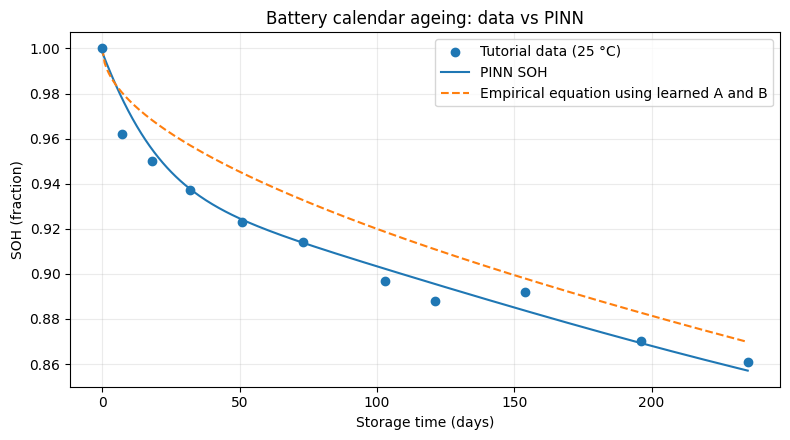

In [ ]:
model.eval()
with torch.no_grad():
    s_plot = torch.linspace(0.0, 1.0, 300).reshape(-1, 1)
    q_plot = model(s_plot).squeeze().numpy()
    q_formula = (1.0 - model.A * torch.sqrt(s_plot) - model.B * s_plot).squeeze().numpy()
    rmse = torch.sqrt(((model(s_data) - soh_data)**2).mean()).item()
    A_fit, B_fit = model.A.item(), model.B.item()

print(f'Learned empirical parameters: A={A_fit:.6f}, B={B_fit:.6f}')
print(f'TRAINING RMSE = {rmse:.5f} SOH fraction ({100*rmse:.2f} percentage points)')
print('These are fitted values')

plt.figure(figsize=(8, 4.5))
plt.scatter(DAYS, soh_data.squeeze().numpy(), label='Tutorial data (25 °C)', zorder=3)
plt.plot(s_plot.squeeze().numpy()*MAX_DAYS, q_plot, label='PINN SOH')
plt.plot(s_plot.squeeze().numpy()*MAX_DAYS, q_formula, '--',
         label='Empirical equation using learned A and B')
plt.xlabel('Storage time (days)')
plt.ylabel('SOH (fraction)')
plt.title('Battery calendar ageing: data vs PINN')
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig('beginner_pinn_notebook_prediction.png', dpi=160)
plt.show()

## Step 6 — Inspect the training losses



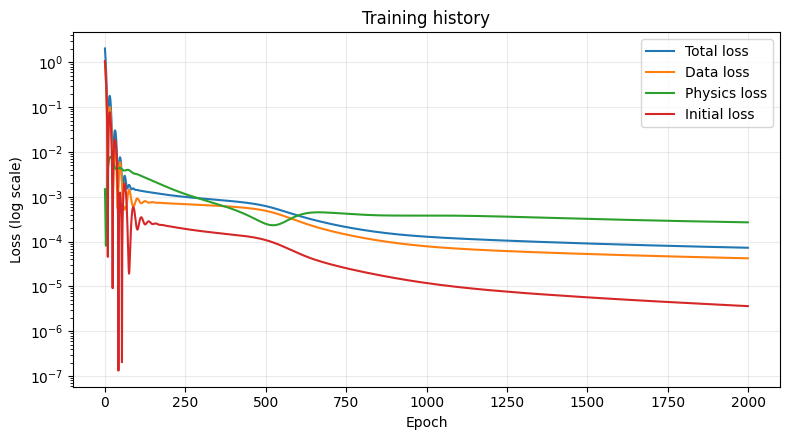

In [ ]:
hist = np.asarray(history)
plt.figure(figsize=(8, 4.5))
for column, label in enumerate(['Total loss', 'Data loss', 'Physics loss', 'Initial loss']):
    plt.semilogy(np.maximum(hist[:, column], 1e-12), label=label)
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.title('Training history')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('beginner_pinn_notebook_losses.png', dpi=160)
plt.show()